# Held-out distribution reconstruction

This notebook evaluates strict leave-one-stage-out (LOSO) gastrulation models at E8.0 and E8.5. Each model starts from the observed E7.5 cells and predicts the omitted stage without using that stage during trajectory training.

The quantitative scores are calculated in **normalized RNA PCA50 and ATAC LSI14**, never in UMAP. UMAP is used afterward only to compare predicted and observed RNA distributions in one shared visual frame.

## Required results

Run balanced and unbalanced LOSO training for both middle stages first. The four output folders must contain `result.json` and `heldout_prediction.npz`:

```bash
python -m examples.gastrulation.train_balanced_loso --held-out-stage E8.0 --output outputs/gastrulation-balanced-loo-e8.0
python -m examples.gastrulation.train_unbalanced_loso --held-out-stage E8.0 --output outputs/gastrulation-unbalanced-loo-e8.0
python -m examples.gastrulation.train_balanced_loso --held-out-stage E8.5 --output outputs/gastrulation-balanced-loo-e8.5
python -m examples.gastrulation.train_unbalanced_loso --held-out-stage E8.5 --output outputs/gastrulation-unbalanced-loo-e8.5
```

The supplied runs use the strict held-out FiLM map for the corresponding stage.

In [1]:
from pathlib import Path
import json
import sys

project_dir = next((p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "pyproject.toml").exists() and (p / "src/coati").is_dir()), None)
if project_dir is None:
    raise FileNotFoundError("Run this notebook inside a COATI checkout.")
example_dir = project_dir / "examples"
if str(example_dir) not in sys.path:
    sys.path.insert(0, str(example_dir))

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.neighbors import KNeighborsRegressor

from coati.downstream import evaluate_paired_distributions
from gastrulation.pretrained import fit_gastrulation_umap

%matplotlib inline
plt.rcParams.update({"font.family": "Arial", "font.size": 11})

In [2]:
data_path = project_dir / "examples/gastrulation/data/gastrulation_embeddings.h5ad"
cells = ad.read_h5ad(data_path)

run_specs = [
    ("Balanced", "E8.0", project_dir / "outputs/gastrulation-balanced-loo-e8.0"),
    ("Unbalanced", "E8.0", project_dir / "outputs/gastrulation-unbalanced-loo-e8.0"),
    ("Balanced", "E8.5", project_dir / "outputs/gastrulation-balanced-loo-e8.5"),
    ("Unbalanced", "E8.5", project_dir / "outputs/gastrulation-unbalanced-loo-e8.5"),
]

runs = {}
for model, stage, directory in run_specs:
    metadata = json.loads((directory / "result.json").read_text())
    with np.load(directory / "heldout_prediction.npz", allow_pickle=False) as archive:
        prediction = {key: np.asarray(archive[key]) for key in archive.files}
    runs[(model, stage)] = {"metadata": metadata, "prediction": prediction}

[(model, stage, runs[(model, stage)]["prediction"]["primary"].shape)
 for model, stage, _ in run_specs]

[('Balanced', 'E8.0', (9018, 50)),
 ('Unbalanced', 'E8.0', (9018, 50)),
 ('Balanced', 'E8.5', (9018, 50)),
 ('Unbalanced', 'E8.5', (9018, 50))]

## Six distribution scores

Three metrics are calculated independently in RNA and ATAC:

- **Support recall ↑**: for every real held-out cell, use its 15-nearest-neighbor radius in the real distribution, measure the normalized predicted mass inside that radius, and convert it to an expected hit probability using the effective particle count.
- **Sinkhorn-based $W_2$ ↓**: approximate each distribution with at most 512 weighted microclusters and report $\sqrt{2S_\varepsilon}$, where $S_\varepsilon$ is the debiased Sinkhorn divergence with $p=2$ and blur 0.05.
- **Composition similarity ↑**: transfer cell types to predicted particles by 1-nearest-neighbor matching in the corresponding modality, exclude `unknown`, and report $1-\sqrt{\mathrm{JSD}_{2}}$.

Balanced predictions use equal particle weights. Unbalanced predictions use their normalized native masses. These metrics compare distribution shape and composition; they do not test the total number of cells.

In [3]:
records = []
for model, stage, _ in run_specs:
    item = runs[(model, stage)]
    metadata = item["metadata"]
    prediction = item["prediction"]
    held_out = np.isclose(cells.obs["time"].to_numpy(dtype=float), float(prediction["time"]))
    labels = cells.obs.loc[held_out, "celltype"].astype(str).to_numpy()

    paired = evaluate_paired_distributions(
        prediction["primary"] / metadata["primary_scale"],
        np.asarray(cells.obsm["X_pca"][held_out]) / metadata["primary_scale"],
        labels,
        prediction["secondary"] / metadata["secondary_scale"],
        np.asarray(cells.obsm["X_atac"][held_out]) / metadata["secondary_scale"],
        labels,
        log_weights=prediction.get("log_weights"),
        support_k=15,
        max_clusters=512,
        sinkhorn_blur=0.05,
        unknown_label="unknown",
    )
    scores = {key.replace("primary_", "rna_").replace("secondary_", "atac_"): value
              for key, value in paired.items()}
    records.append({"Model": model, "Held out": stage, **scores})

metrics = pd.DataFrame(records)
score_columns = [
    "Model", "Held out", "rna_support_recall", "atac_support_recall",
    "rna_sinkhorn_w2", "atac_sinkhorn_w2",
    "rna_composition_similarity", "atac_composition_similarity",
]
display(metrics[score_columns].style.format(precision=4))

,Model,Held out,rna_support_recall,atac_support_recall,rna_sinkhorn_w2,atac_sinkhorn_w2,rna_composition_similarity,atac_composition_similarity
0,Balanced,E8.0,0.3183,0.6232,0.5398,0.5429,0.8336,0.8495
1,Unbalanced,E8.0,0.3036,0.6669,0.5486,0.5003,0.8661,0.8745
2,Balanced,E8.5,0.7033,0.8171,0.4592,0.3778,0.8517,0.8466
3,Unbalanced,E8.5,0.7380,0.8158,0.4438,0.3705,0.8590,0.8599


## Prediction and truth in one global RNA UMAP

Fit the global reference UMAP once on all 35,503 observed RNA PCA50 rows using the fixed gastrulation parameters: 30 neighbors, `min_dist=0.5`, Euclidean distance, spectral initialization, and seed 42. The observed held-out cells use the fitted reference coordinates.

To avoid fitting a new UMAP to each prediction, a distance-weighted 30-nearest-neighbor regressor is fitted once from the observed PCA50 atlas to its reference UMAP coordinates. It then projects every predicted cell into that same atlas. This stable projection does not require a serialized UMAP model.

The panels therefore share one coordinate system. No model is evaluated in UMAP, and no embedding is fitted separately to a prediction.

In [4]:
reference_path = project_dir / "examples/gastrulation/data/pretrained/rna_pca_by_time.npz"
umap_model = fit_gastrulation_umap(reference_path)
reference_umap = np.asarray(umap_model.embedding_)

with np.load(reference_path, allow_pickle=False) as archive:
    reference_pca = np.concatenate([archive[key] for key in ("time0", "time1", "time2", "time3")])
np.testing.assert_array_equal(reference_pca, np.asarray(cells.obsm["X_pca"]))

atlas_projection = KNeighborsRegressor(
    n_neighbors=30, weights="distance", n_jobs=-1,
).fit(reference_pca, reference_umap)
prediction_umap = {
    key: atlas_projection.predict(item["prediction"]["primary"])
    for key, item in runs.items()
}
print("Reference:", reference_umap.shape, "Predictions:",
      {key: value.shape for key, value in prediction_umap.items()})

/Users/jingfeng/local/project/COATI/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Reference: (35503, 2) Predictions: {('Balanced', 'E8.0'): (9018, 2), ('Unbalanced', 'E8.0'): (9018, 2), ('Balanced', 'E8.5'): (9018, 2), ('Unbalanced', 'E8.5'): (9018, 2)}


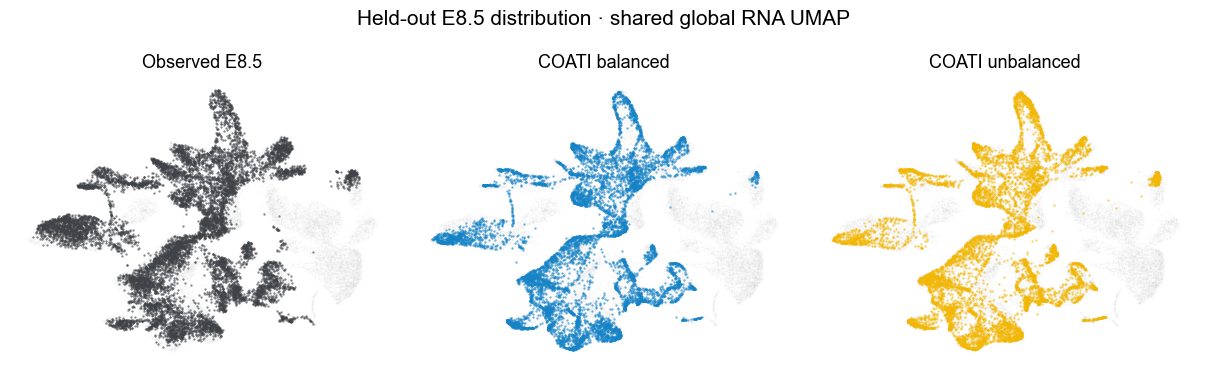

In [5]:
def plot_held_out_stage(stage):
    stage_time = {"E8.0": 1.0, "E8.5": 2.0}[stage]
    observed = np.isclose(cells.obs["time"].to_numpy(dtype=float), stage_time)
    panels = [
        (f"Observed {stage}", reference_umap[observed], "#3F4246"),
        ("COATI balanced", prediction_umap[("Balanced", stage)], "#1683C7"),
        ("COATI unbalanced", prediction_umap[("Unbalanced", stage)], "#F2B705"),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(12.2, 3.8), sharex=True, sharey=True)
    for ax, (title, coordinates, color) in zip(axes, panels):
        ax.scatter(reference_umap[:, 0], reference_umap[:, 1], s=1.2,
                   color="#D8DADD", alpha=.10, linewidths=0, rasterized=True)
        ax.scatter(coordinates[:, 0], coordinates[:, 1], s=2.8,
                   color=color, alpha=.62, linewidths=0, rasterized=True)
        ax.set_title(title, fontsize=13)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    fig.suptitle(f"Held-out {stage} distribution · shared global RNA UMAP", fontsize=15)
    fig.tight_layout()
    return fig

plot_held_out_stage("E8.5");

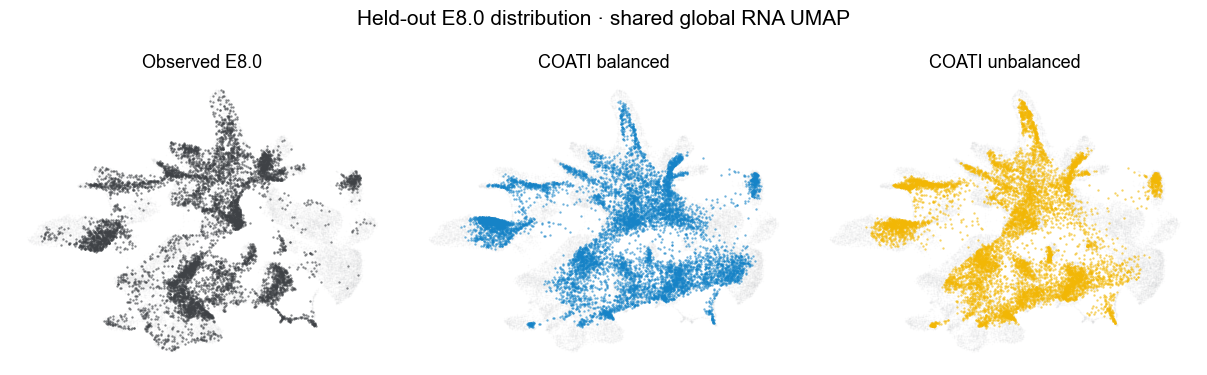

In [6]:
plot_held_out_stage("E8.0");

The UMAP panels are a qualitative support check. Broad overlap can coexist with local density or cell-type composition errors, so the six PCA/LSI-space scores remain the primary evaluation. In the current runs, E8.0 is harder to reconstruct than E8.5; unbalanced training generally improves ATAC and composition agreement, while balanced training retains a small RNA geometric advantage at E8.0.